# ARIMA Sales Forecasting: Shampoo and Beer
**Joanne Mesadieu**

This notebook adapts the provided `ARIMA.ipynb` and runs ARIMA(5,1,0) on both uploaded datasets. It saves actual-versus-predicted sales plots and aligned CSV results automatically. Run all cells in order.

The notebook contains the small source CSVs and analysis script for portability. With Python 3.12, install `requirements.txt` first when running locally. Standard Colab environments normally include the main scientific packages.

Evaluation uses the first 66% of months for initial training and expanding-window one-step forecasting over the remainder. The actual sale for a test month is revealed only after that month's forecast. These are not in-sample fitted values or a single fixed-origin multi-month forecast.

In [1]:
from pathlib import Path
import json, runpy
PROJECT_NAME = 'ARIMA_Sales_Forecasting'
ROOT = Path.cwd() if Path.cwd().name == PROJECT_NAME else Path.cwd()/PROJECT_NAME
for folder in ['src','data','figures','results']:
    (ROOT/folder).mkdir(parents=True,exist_ok=True)
DATASETS = {'shampoo.csv': '"Month","Sales"\n"1-01",266.0\n"1-02",145.9\n"1-03",183.1\n"1-04",119.3\n"1-05",180.3\n"1-06",168.5\n"1-07",231.8\n"1-08",224.5\n"1-09",192.8\n"1-10",122.9\n"1-11",336.5\n"1-12",185.9\n"2-01",194.3\n"2-02",149.5\n"2-03",210.1\n"2-04",273.3\n"2-05",191.4\n"2-06",287.0\n"2-07",226.0\n"2-08",303.6\n"2-09",289.9\n"2-10",421.6\n"2-11",264.5\n"2-12",342.3\n"3-01",339.7\n"3-02",440.4\n"3-03",315.9\n"3-04",439.3\n"3-05",401.3\n"3-06",437.4\n"3-07",575.5\n"3-08",407.6\n"3-09",682.0\n"3-10",475.3\n"3-11",581.3\n"3-12",646.9', 'BeerWineLiquor.csv': 'date,beer\n1/1/1992,1509\n2/1/1992,1541\n3/1/1992,1597\n4/1/1992,1675\n5/1/1992,1822\n6/1/1992,1775\n7/1/1992,1912\n8/1/1992,1862\n9/1/1992,1770\n10/1/1992,1882\n11/1/1992,1831\n12/1/1992,2511\n1/1/1993,1614\n2/1/1993,1529\n3/1/1993,1678\n4/1/1993,1713\n5/1/1993,1796\n6/1/1993,1792\n7/1/1993,1950\n8/1/1993,1777\n9/1/1993,1707\n10/1/1993,1757\n11/1/1993,1782\n12/1/1993,2443\n1/1/1994,1548\n2/1/1994,1505\n3/1/1994,1714\n4/1/1994,1757\n5/1/1994,1830\n6/1/1994,1857\n7/1/1994,1981\n8/1/1994,1858\n9/1/1994,1823\n10/1/1994,1806\n11/1/1994,1845\n12/1/1994,2577\n1/1/1995,1555\n2/1/1995,1501\n3/1/1995,1725\n4/1/1995,1699\n5/1/1995,1807\n6/1/1995,1863\n7/1/1995,1886\n8/1/1995,1861\n9/1/1995,1845\n10/1/1995,1788\n11/1/1995,1879\n12/1/1995,2598\n1/1/1996,1679\n2/1/1996,1652\n3/1/1996,1837\n4/1/1996,1798\n5/1/1996,1957\n6/1/1996,1958\n7/1/1996,2034\n8/1/1996,2062\n9/1/1996,1781\n10/1/1996,1860\n11/1/1996,1992\n12/1/1996,2547\n1/1/1997,1706\n2/1/1997,1621\n3/1/1997,1853\n4/1/1997,1817\n5/1/1997,2060\n6/1/1997,2002\n7/1/1997,2098\n8/1/1997,2079\n9/1/1997,1892\n10/1/1997,2050\n11/1/1997,2082\n12/1/1997,2821\n1/1/1998,1846\n2/1/1998,1768\n3/1/1998,1894\n4/1/1998,1963\n5/1/1998,2140\n6/1/1998,2059\n7/1/1998,2209\n8/1/1998,2118\n9/1/1998,2031\n10/1/1998,2163\n11/1/1998,2154\n12/1/1998,3037\n1/1/1999,1866\n2/1/1999,1808\n3/1/1999,1986\n4/1/1999,2099\n5/1/1999,2210\n6/1/1999,2145\n7/1/1999,2339\n8/1/1999,2140\n9/1/1999,2126\n10/1/1999,2219\n11/1/1999,2273\n12/1/1999,3265\n1/1/2000,1920\n2/1/2000,1976\n3/1/2000,2190\n4/1/2000,2132\n5/1/2000,2357\n6/1/2000,2413\n7/1/2000,2463\n8/1/2000,2422\n9/1/2000,2358\n10/1/2000,2352\n11/1/2000,2549\n12/1/2000,3375\n1/1/2001,2109\n2/1/2001,2052\n3/1/2001,2327\n4/1/2001,2231\n5/1/2001,2470\n6/1/2001,2526\n7/1/2001,2483\n8/1/2001,2518\n9/1/2001,2316\n10/1/2001,2409\n11/1/2001,2638\n12/1/2001,3542\n1/1/2002,2114\n2/1/2002,2109\n3/1/2002,2366\n4/1/2002,2300\n5/1/2002,2569\n6/1/2002,2486\n7/1/2002,2568\n8/1/2002,2595\n9/1/2002,2297\n10/1/2002,2401\n11/1/2002,2601\n12/1/2002,3488\n1/1/2003,2121\n2/1/2003,2046\n3/1/2003,2273\n4/1/2003,2333\n5/1/2003,2576\n6/1/2003,2433\n7/1/2003,2611\n8/1/2003,2660\n9/1/2003,2461\n10/1/2003,2641\n11/1/2003,2660\n12/1/2003,3654\n1/1/2004,2293\n2/1/2004,2219\n3/1/2004,2398\n4/1/2004,2553\n5/1/2004,2685\n6/1/2004,2643\n7/1/2004,2867\n8/1/2004,2622\n9/1/2004,2618\n10/1/2004,2727\n11/1/2004,2763\n12/1/2004,3801\n1/1/2005,2219\n2/1/2005,2316\n3/1/2005,2530\n4/1/2005,2640\n5/1/2005,2709\n6/1/2005,2783\n7/1/2005,2924\n8/1/2005,2791\n9/1/2005,2784\n10/1/2005,2801\n11/1/2005,2933\n12/1/2005,4137\n1/1/2006,2424\n2/1/2006,2519\n3/1/2006,2753\n4/1/2006,2791\n5/1/2006,3017\n6/1/2006,3055\n7/1/2006,3117\n8/1/2006,3024\n9/1/2006,2997\n10/1/2006,2913\n11/1/2006,3137\n12/1/2006,4269\n1/1/2007,2569\n2/1/2007,2603\n3/1/2007,3005\n4/1/2007,2867\n5/1/2007,3262\n6/1/2007,3364\n7/1/2007,3322\n8/1/2007,3292\n9/1/2007,3057\n10/1/2007,3087\n11/1/2007,3297\n12/1/2007,4403\n1/1/2008,2675\n2/1/2008,2806\n3/1/2008,2989\n4/1/2008,2997\n5/1/2008,3420\n6/1/2008,3279\n7/1/2008,3517\n8/1/2008,3472\n9/1/2008,3151\n10/1/2008,3351\n11/1/2008,3386\n12/1/2008,4461\n1/1/2009,2913\n2/1/2009,2781\n3/1/2009,3024\n4/1/2009,3130\n5/1/2009,3467\n6/1/2009,3307\n7/1/2009,3555\n8/1/2009,3399\n9/1/2009,3263\n10/1/2009,3425\n11/1/2009,3356\n12/1/2009,4625\n1/1/2010,2878\n2/1/2010,2916\n3/1/2010,3214\n4/1/2010,3310\n5/1/2010,3467\n6/1/2010,3438\n7/1/2010,3657\n8/1/2010,3454\n9/1/2010,3365\n10/1/2010,3497\n11/1/2010,3524\n12/1/2010,4681\n1/1/2011,2888\n2/1/2011,2984\n3/1/2011,3249\n4/1/2011,3363\n5/1/2011,3471\n6/1/2011,3551\n7/1/2011,3740\n8/1/2011,3576\n9/1/2011,3517\n10/1/2011,3515\n11/1/2011,3646\n12/1/2011,4892\n1/1/2012,2995\n2/1/2012,3202\n3/1/2012,3550\n4/1/2012,3409\n5/1/2012,3786\n6/1/2012,3816\n7/1/2012,3733\n8/1/2012,3752\n9/1/2012,3503\n10/1/2012,3626\n11/1/2012,3869\n12/1/2012,5124\n1/1/2013,3155\n2/1/2013,3227\n3/1/2013,3624\n4/1/2013,3488\n5/1/2013,3947\n6/1/2013,3809\n7/1/2013,4034\n8/1/2013,4100\n9/1/2013,3631\n10/1/2013,3787\n11/1/2013,4059\n12/1/2013,5215\n1/1/2014,3381\n2/1/2014,3310\n3/1/2014,3652\n4/1/2014,3702\n5/1/2014,4165\n6/1/2014,4036\n7/1/2014,4242\n8/1/2014,4219\n9/1/2014,3814\n10/1/2014,4090\n11/1/2014,4103\n12/1/2014,5572\n1/1/2015,3572\n2/1/2015,3482\n3/1/2015,3857\n4/1/2015,3867\n5/1/2015,4335\n6/1/2015,4217\n7/1/2015,4532\n8/1/2015,4260\n9/1/2015,4073\n10/1/2015,4273\n11/1/2015,4266\n12/1/2015,5816\n1/1/2016,3610\n2/1/2016,3773\n3/1/2016,4051\n4/1/2016,4114\n5/1/2016,4403\n6/1/2016,4474\n7/1/2016,4751\n8/1/2016,4480\n9/1/2016,4434\n10/1/2016,4437\n11/1/2016,4674\n12/1/2016,6054\n1/1/2017,3728\n2/1/2017,3759\n3/1/2017,4247\n4/1/2017,4251\n5/1/2017,4647\n6/1/2017,4676\n7/1/2017,4798\n8/1/2017,4647\n9/1/2017,4538\n10/1/2017,4536\n11/1/2017,4846\n12/1/2017,6241\n1/1/2018,3965\n2/1/2018,3967\n3/1/2018,4629\n4/1/2018,4317\n5/1/2018,4897\n6/1/2018,4939\n7/1/2018,4963\n8/1/2018,4898\n9/1/2018,4598\n10/1/2018,4737\n11/1/2018,5130\n12/1/2018,6370\n'}
for name,text in DATASETS.items():
    (ROOT/'data'/name).write_text(text,encoding='utf-8')
SOURCE = '"""Reproduce supplied ARIMA(5,1,0) walk-forward method on both sales files."""\nfrom pathlib import Path\nimport json, warnings, platform\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nimport matplotlib.dates as mdates\nfrom statsmodels.tsa.arima.model import ARIMA\nimport statsmodels\nfrom threadpoolctl import threadpool_limits\n\nROOT=Path(__file__).resolve().parents[1]\nORDER=(5,1,0)\nTRAIN_FRACTION=.66\n\ndef load_sales(name):\n    """Parse source dates explicitly; reject missing, duplicate or gapped months."""\n    if name==\'shampoo\':\n        frame=pd.read_csv(ROOT/\'data/shampoo.csv\')\n        # The teaching file has relative years 1–3. Preserve its original\n        # parser\'s display convention (1901–1903), not asserted historical dates.\n        dates=pd.to_datetime(\'190\'+frame[\'Month\'].astype(str),format=\'%Y-%m\')\n        values=pd.to_numeric(frame[\'Sales\'],errors=\'raise\')\n    else:\n        frame=pd.read_csv(ROOT/\'data/BeerWineLiquor.csv\')\n        dates=pd.to_datetime(frame[\'date\'],format=\'%m/%d/%Y\')\n        values=pd.to_numeric(frame[\'beer\'],errors=\'raise\')\n    series=pd.Series(values.to_numpy(dtype=float),index=pd.DatetimeIndex(dates),name=\'sales\').sort_index()\n    if series.index.has_duplicates: raise ValueError(\'Duplicate dates in \'+name)\n    series=series.asfreq(\'MS\')\n    if series.isna().any() or not np.isfinite(series.to_numpy()).all():\n        raise ValueError(\'Missing/nonfinite observations or missing months in \'+name)\n    return series\n\ndef evaluate_forecasts(actual,predicted):\n    a,p=np.asarray(actual,dtype=float),np.asarray(predicted,dtype=float)\n    if a.shape!=p.shape or len(a)==0: raise ValueError(\'Invalid forecast alignment\')\n    error=a-p\n    nonzero=a!=0\n    return dict(MAE=float(np.abs(error).mean()),RMSE=float(np.sqrt(np.mean(error**2))),\n                MAPE_percent=float(np.mean(np.abs(error[nonzero]/a[nonzero]))*100) if nonzero.any() else None)\n\ndef walk_forward_forecast(series):\n    """Fit, predict next month, then reveal that month\'s actual observation."""\n    split=int(len(series)*TRAIN_FRACTION)\n    train,test=series.iloc[:split],series.iloc[split:]\n    history=train.to_numpy().tolist(); records=[]; warning_rows=[]\n    for date,actual in test.items():\n        # Fixed order was supplied by the instructor; no hold-out tuning.\n        with warnings.catch_warnings(record=True) as caught:\n            warnings.simplefilter(\'always\')\n            fitted=ARIMA(np.asarray(history,dtype=float),order=ORDER).fit()\n        fc=fitted.get_forecast(steps=1)\n        mean=float(np.asarray(fc.predicted_mean)[0])\n        lower,upper=np.asarray(fc.conf_int(alpha=.05))[0]\n        records.append(dict(date=date,actual=float(actual),predicted=mean,\n                            lower_95=float(lower),upper_95=float(upper),\n                            naive_last_month=float(history[-1]),\n                            seasonal_naive_12=float(history[-12]),training_observations=len(history),\n                            optimizer_converged=bool(fitted.mle_retvals.get(\'converged\',True))))\n        for w in caught:\n            warning_rows.append(dict(date=str(date.date()),category=w.category.__name__,message=str(w.message)))\n        history.append(float(actual))\n    forecasts=pd.DataFrame(records).set_index(\'date\')\n    assert forecasts.index.equals(test.index)\n    assert forecasts.training_observations.to_list()==list(range(split,len(series)))\n    return train,test,forecasts,warning_rows\n\ndef plot_actual_vs_predicted(name,series,train,forecasts,metrics):\n    title=\'Shampoo\' if name==\'shampoo\' else \'Beer (BeerWineLiquor.csv, beer column)\'\n    fig,axes=plt.subplots(2,1,figsize=(13,9),gridspec_kw={\'height_ratios\':[1,1.2]},layout=\'constrained\')\n    ax=axes[0]\n    ax.plot(series.index,series.values,color=\'#143d59\',lw=1.6,label=\'Actual sales\')\n    ax.plot(forecasts.index,forecasts.predicted,color=\'#e76f51\',lw=1.5,ls=\'--\',label=\'One-step ARIMA predictions\')\n    ax.axvline(forecasts.index[0],color=\'#555\',ls=\':\',label=\'Start of test period\')\n    ax.axvspan(forecasts.index[0],forecasts.index[-1],color=\'#e9c46a\',alpha=.12)\n    ax.set_title(\'Full series and chronological train/test split\',fontsize=12)\n    ax.set_ylabel(\'Sales (source units)\'); ax.legend(loc=\'upper left\',fontsize=9,ncol=2);ax.grid(alpha=.18)\n    ax=axes[1]\n    ax.plot(forecasts.index,forecasts.actual,color=\'#143d59\',lw=2,marker=\'o\',ms=3,label=\'Actual test sales\')\n    ax.plot(forecasts.index,forecasts.predicted,color=\'#e76f51\',lw=1.8,ls=\'--\',marker=\'s\',ms=3,label=\'Predicted sales\')\n    ax.fill_between(forecasts.index,forecasts.lower_95,forecasts.upper_95,color=\'#e76f51\',alpha=.15,label=\'95% one-step prediction interval\')\n    ax.set_title(f\'Test-period comparison | RMSE = {metrics["RMSE"]:.2f} | MAE = {metrics["MAE"]:.2f}\',fontsize=12)\n    ax.set(xlabel=\'Month\',ylabel=\'Sales (source units)\');ax.legend(loc=\'upper left\',fontsize=9);ax.grid(alpha=.18)\n    for ax in axes:\n        locator=mdates.AutoDateLocator(minticks=5,maxticks=10)\n        ax.xaxis.set_major_locator(locator);ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))\n    subtitle=f\'ARIMA{ORDER} | {len(train)} initial training months, {len(forecasts)} walk-forward test months\'\n    if name==\'shampoo\': subtitle+=\'\\n1901–1903 are display placeholders for source years 1–3.\'\n    fig.suptitle(title+\' Sales: Actual vs Predicted\\n\'+subtitle,fontsize=16,fontweight=\'bold\')\n    fig.savefig(ROOT/f\'figures/{name}_arima_actual_vs_predicted.png\',dpi=300,bbox_inches=\'tight\');plt.close(fig)\n\ndef main():\n    for folder in [\'figures\',\'results\']: (ROOT/folder).mkdir(exist_ok=True,parents=True)\n    metric_rows=[]; details={}; all_warnings=[]\n    for name in [\'shampoo\',\'beer\']:\n        series=load_sales(name)\n        print(f\'Forecasting {name}: {len(series)} monthly observations\',flush=True)\n        train,test,forecasts,warning_rows=walk_forward_forecast(series)\n        forecasts.to_csv(ROOT/f\'results/{name}_actual_vs_predicted.csv\',date_format=\'%Y-%m-%d\')\n        for model,col in [(\'ARIMA(5,1,0)\',\'predicted\'),(\'Naive: last month\',\'naive_last_month\'),(\'Seasonal naive: last year\',\'seasonal_naive_12\')]:\n            metric_rows.append(dict(dataset=name,model=model,train_months=len(train),test_months=len(test),\n                                    **evaluate_forecasts(forecasts.actual,forecasts[col])))\n        arima_metrics=evaluate_forecasts(forecasts.actual,forecasts.predicted)\n        plot_actual_vs_predicted(name,series,train,forecasts,arima_metrics)\n        details[name]=dict(total_months=len(series),train_months=len(train),test_months=len(test),\n                           start=str(series.index[0].date()),end=str(series.index[-1].date()),\n                           test_start=str(test.index[0].date()),test_end=str(test.index[-1].date()),\n                           interval_coverage=float(((forecasts.actual>=forecasts.lower_95)&(forecasts.actual<=forecasts.upper_95)).mean()),\n                           failed_convergence=int((~forecasts.optimizer_converged).sum()))\n        all_warnings.extend(dict(dataset=name,**row) for row in warning_rows)\n        print(f\'{name}: RMSE {arima_metrics["RMSE"]:.3f}; MAE {arima_metrics["MAE"]:.3f}\',flush=True)\n    metrics=pd.DataFrame(metric_rows);metrics.to_csv(ROOT/\'results/forecast_metrics.csv\',index=False)\n    pd.DataFrame(all_warnings,columns=[\'dataset\',\'date\',\'category\',\'message\']).to_csv(ROOT/\'results/fit_warnings.csv\',index=False)\n    details[\'configuration\']=dict(order=list(ORDER),train_fraction=TRAIN_FRACTION,\n        method=\'Expanding-window, one-step-ahead, refit at every test month\',\n        versions=dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,statsmodels=statsmodels.__version__,matplotlib=matplotlib.__version__))\n    (ROOT/\'results/run_summary.json\').write_text(json.dumps(details,indent=2),encoding=\'utf-8\')\n    write_readme(metrics,details)\n    print(metrics.round(3).to_string(index=False),flush=True)\n    return metrics\n\ndef write_readme(metrics,details):\n    rows=[\'| Dataset | Model | Train months | Test months | MAE | RMSE | MAPE (%) |\',\n          \'|---|---|---:|---:|---:|---:|---:|\']\n    for _,r in metrics.iterrows():\n        rows.append(f\'| {r.dataset.title()} | {r.model} | {r.train_months} | {r.test_months} | {r.MAE:.3f} | {r.RMSE:.3f} | {r.MAPE_percent:.2f} |\')\n    interpretation=[]\n    for name in [\'shampoo\',\'beer\']:\n        t=metrics[metrics.dataset==name];a=t[t.model==\'ARIMA(5,1,0)\'].iloc[0];best=t.loc[t.RMSE.idxmin()]\n        interpretation.append(f\'{name.title()}: ARIMA RMSE is {a.RMSE:.3f}. The lowest-RMSE method among these three fixed methods is {best.model} ({best.RMSE:.3f}).\')\n    text=\'\\n\\n\'.join([\'# ARIMA Sales Forecasting — Shampoo and Beer\',\'Joanne Mesadieu\',\n      \'Forecast monthly shampoo and beer sales using the supplied ARIMA notebook and upload plots comparing predictions with actual sales.\',\n      \'## Required plots\',\'![Shampoo actual vs predicted](figures/shampoo_arima_actual_vs_predicted.png)\\n\\n![Beer actual vs predicted](figures/beer_arima_actual_vs_predicted.png)\',\n      \'## Data\',\n      \'The supplied shampoo.csv contains 36 monthly sales observations. Relative source labels 1-01 through 3-12 are displayed as 1901-01 through 1903-12 to match the supplied notebook. These are plotting placeholders, not independently verified calendar years. BeerWineLiquor.csv contains 324 monthly observations from January 1992 through December 2018 in its beer column. The filename is retained; its contents have not been independently verified as beer-only revenue. Sales units are not stated in the uploads, so figures use source units. Both series are checked for missing values, duplicate dates and missing months; no values are imputed.\',\n      \'## Forecasting method\',\n      \'Both series use statsmodels.tsa.arima.model.ARIMA with order=(5,1,0), preserving the supplied example. p=5 uses five autoregressive lags, d=1 differences the series once, and q=0 has no moving-average term. The first int(0.66 × N) observations form the initial training set: 23 shampoo months and 213 beer months. The remaining 13 and 111 months form the test periods. No random shuffle is used.\',\n      \'For every test month: fit ARIMA on the expanding history, predict exactly the next month, save its 95% prediction interval, then add the newly observed actual sale to history. Test observations become available only after their own prediction is made. This is one-step walk-forward evaluation, not a single forecast of the entire test horizon from the original training cutoff. No parameters are tuned using the test results.\',\n      \'## Results\',\'\\n\'.join(rows),\'\\n\\n\'.join(interpretation),\n      \'Metrics are calculated automatically from aligned test-date CSVs. MAE is mean absolute error; RMSE is the square root of mean squared error; MAPE is mean absolute percentage error. Lower is better. Naive and seasonal-naive benchmarks forecast the previous month and the same month one year earlier, respectively, using only available history.\',\n      \'## Interpretation and limitations\',\n      \'The beer series has recurring annual peaks, particularly near year end. A nonseasonal ARIMA(5,1,0) need not reproduce these well; a seasonal ARIMA model with period 12 would be a useful follow-up. The task’s fixed ARIMA specification is retained instead of selecting a different model after viewing the test outcomes. Shampoo has only three years of data, making estimation and evaluation sensitive to a few observations. Prediction intervals depend on model assumptions and are not guarantees. Errors are in each dataset’s original scale and should not be directly compared across datasets.\',\n      f\'Fits not reporting optimizer convergence: shampoo {details["shampoo"]["failed_convergence"]}, beer {details["beer"]["failed_convergence"]}. Full warnings are saved in results/fit_warnings.csv.\',\n      \'## Run\',\n      \'Use Python 3.12. From the repository root:\\n```bash\\npython -m pip install -r requirements.txt\\npython src/arima_forecasting.py\\n```\\nOr run all cells in ARIMA_Sales_Forecasting.ipynb. The notebook is self-contained: it includes the small supplied CSVs and executable analysis source, creates the project folders if necessary, and writes every figure and CSV. The original teaching notebook is preserved in reference/ARIMA_original.ipynb.\',\n      \'## Submission\',\n      \'Publish this project as a public GitHub repository named Joanne_Mesadieu_ARIMA_Sales_Forecasting. Submit the actual repository URL and upload figures/shampoo_arima_actual_vs_predicted.png and figures/beer_arima_actual_vs_predicted.png to the assignment. A repository link is valid only after it has actually been published; no URL is fabricated in this project.\',\n      \'## Software versions\',\'```json\\n\'+json.dumps(details[\'configuration\'][\'versions\'],indent=2)+\'\\n```\',\n      \'## References\',\n      \'Inputs: user-provided shampoo.csv, BeerWineLiquor.csv and ARIMA.ipynb. Documentation: https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html and https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMAResults.get_forecast.html\'])\n    (ROOT/\'README.md\').write_text(text,encoding=\'utf-8\')\n\nif __name__==\'__main__\':\n    with threadpool_limits(limits=1): main()\n'
(ROOT/'src/arima_forecasting.py').write_text(SOURCE,encoding='utf-8')
(ROOT/'requirements.txt').write_text('numpy==2.1.3\npandas==2.2.3\nscipy==1.14.1\nstatsmodels==0.14.4\nmatplotlib==3.9.2\nthreadpoolctl==3.6.0\n',encoding='utf-8')
print('Project:',ROOT)


Project: C:\Users\joann\Documents\Codex\2026-11-11\new-chat\ARIMA_Sales_Forecasting


## 1. Inspect the source data
Shampoo uses relative year-month labels. The original notebook maps years 1–3 to 1901–1903; these dates are kept solely for display. The beer file retains its supplied `BeerWineLiquor.csv` filename and `beer` column. Units are not documented in the uploads.

In [2]:
import pandas as pd
for name in DATASETS:
    frame = pd.read_csv(ROOT/'data'/name)
    print(name, '| rows:',len(frame),'| columns:',list(frame.columns))
    print(frame.head().to_string(index=False))


shampoo.csv | rows: 36 | columns: ['Month', 'Sales']
Month  Sales
 1-01  266.0
 1-02  145.9
 1-03  183.1
 1-04  119.3
 1-05  180.3
BeerWineLiquor.csv | rows: 324 | columns: ['date', 'beer']
    date  beer
1/1/1992  1509
2/1/1992  1541
3/1/1992  1597
4/1/1992  1675
5/1/1992  1822


## 2. Fit and evaluate the ARIMA models
The code preserves order=(5,1,0) from the teaching notebook. Deprecated `pandas.datetime`, `squeeze`, and `date_parser` usage has been replaced. Reusable functions load data, generate forecasts, calculate metrics and save figures. Last-month and last-year naive forecasts provide context; they do not change ARIMA's preselected settings.

In [3]:
runpy.run_path(str(ROOT/'src/arima_forecasting.py'),run_name='__main__')


Forecasting shampoo: 36 monthly observations


shampoo: RMSE 89.021; MAE 68.669


Forecasting beer: 324 monthly observations


beer: RMSE 560.826; MAE 395.876


dataset                     model  train_months  test_months     MAE    RMSE  MAPE_percent
shampoo              ARIMA(5,1,0)            23           13  68.669  89.021        13.298
shampoo         Naive: last month            23           13 112.446 133.156        23.759
shampoo Seasonal naive: last year            23           13 211.192 235.076        43.780
   beer              ARIMA(5,1,0)           213          111 395.876 560.826         9.520
   beer         Naive: last month           213          111 432.261 729.076        10.836
   beer Seasonal naive: last year           213          111 158.441 184.355         3.846


{'__name__': '__main__',
 '__doc__': 'Reproduce supplied ARIMA(5,1,0) walk-forward method on both sales files.',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': 'C:\\Users\\joann\\Documents\\Codex\\2026-11-11\\new-chat\\ARIMA_Sales_Forecasting\\src\\arima_forecasting.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importlib.BuiltinImporter'>, origin='built-in'),
 

## 3. Actual versus predicted sales plots

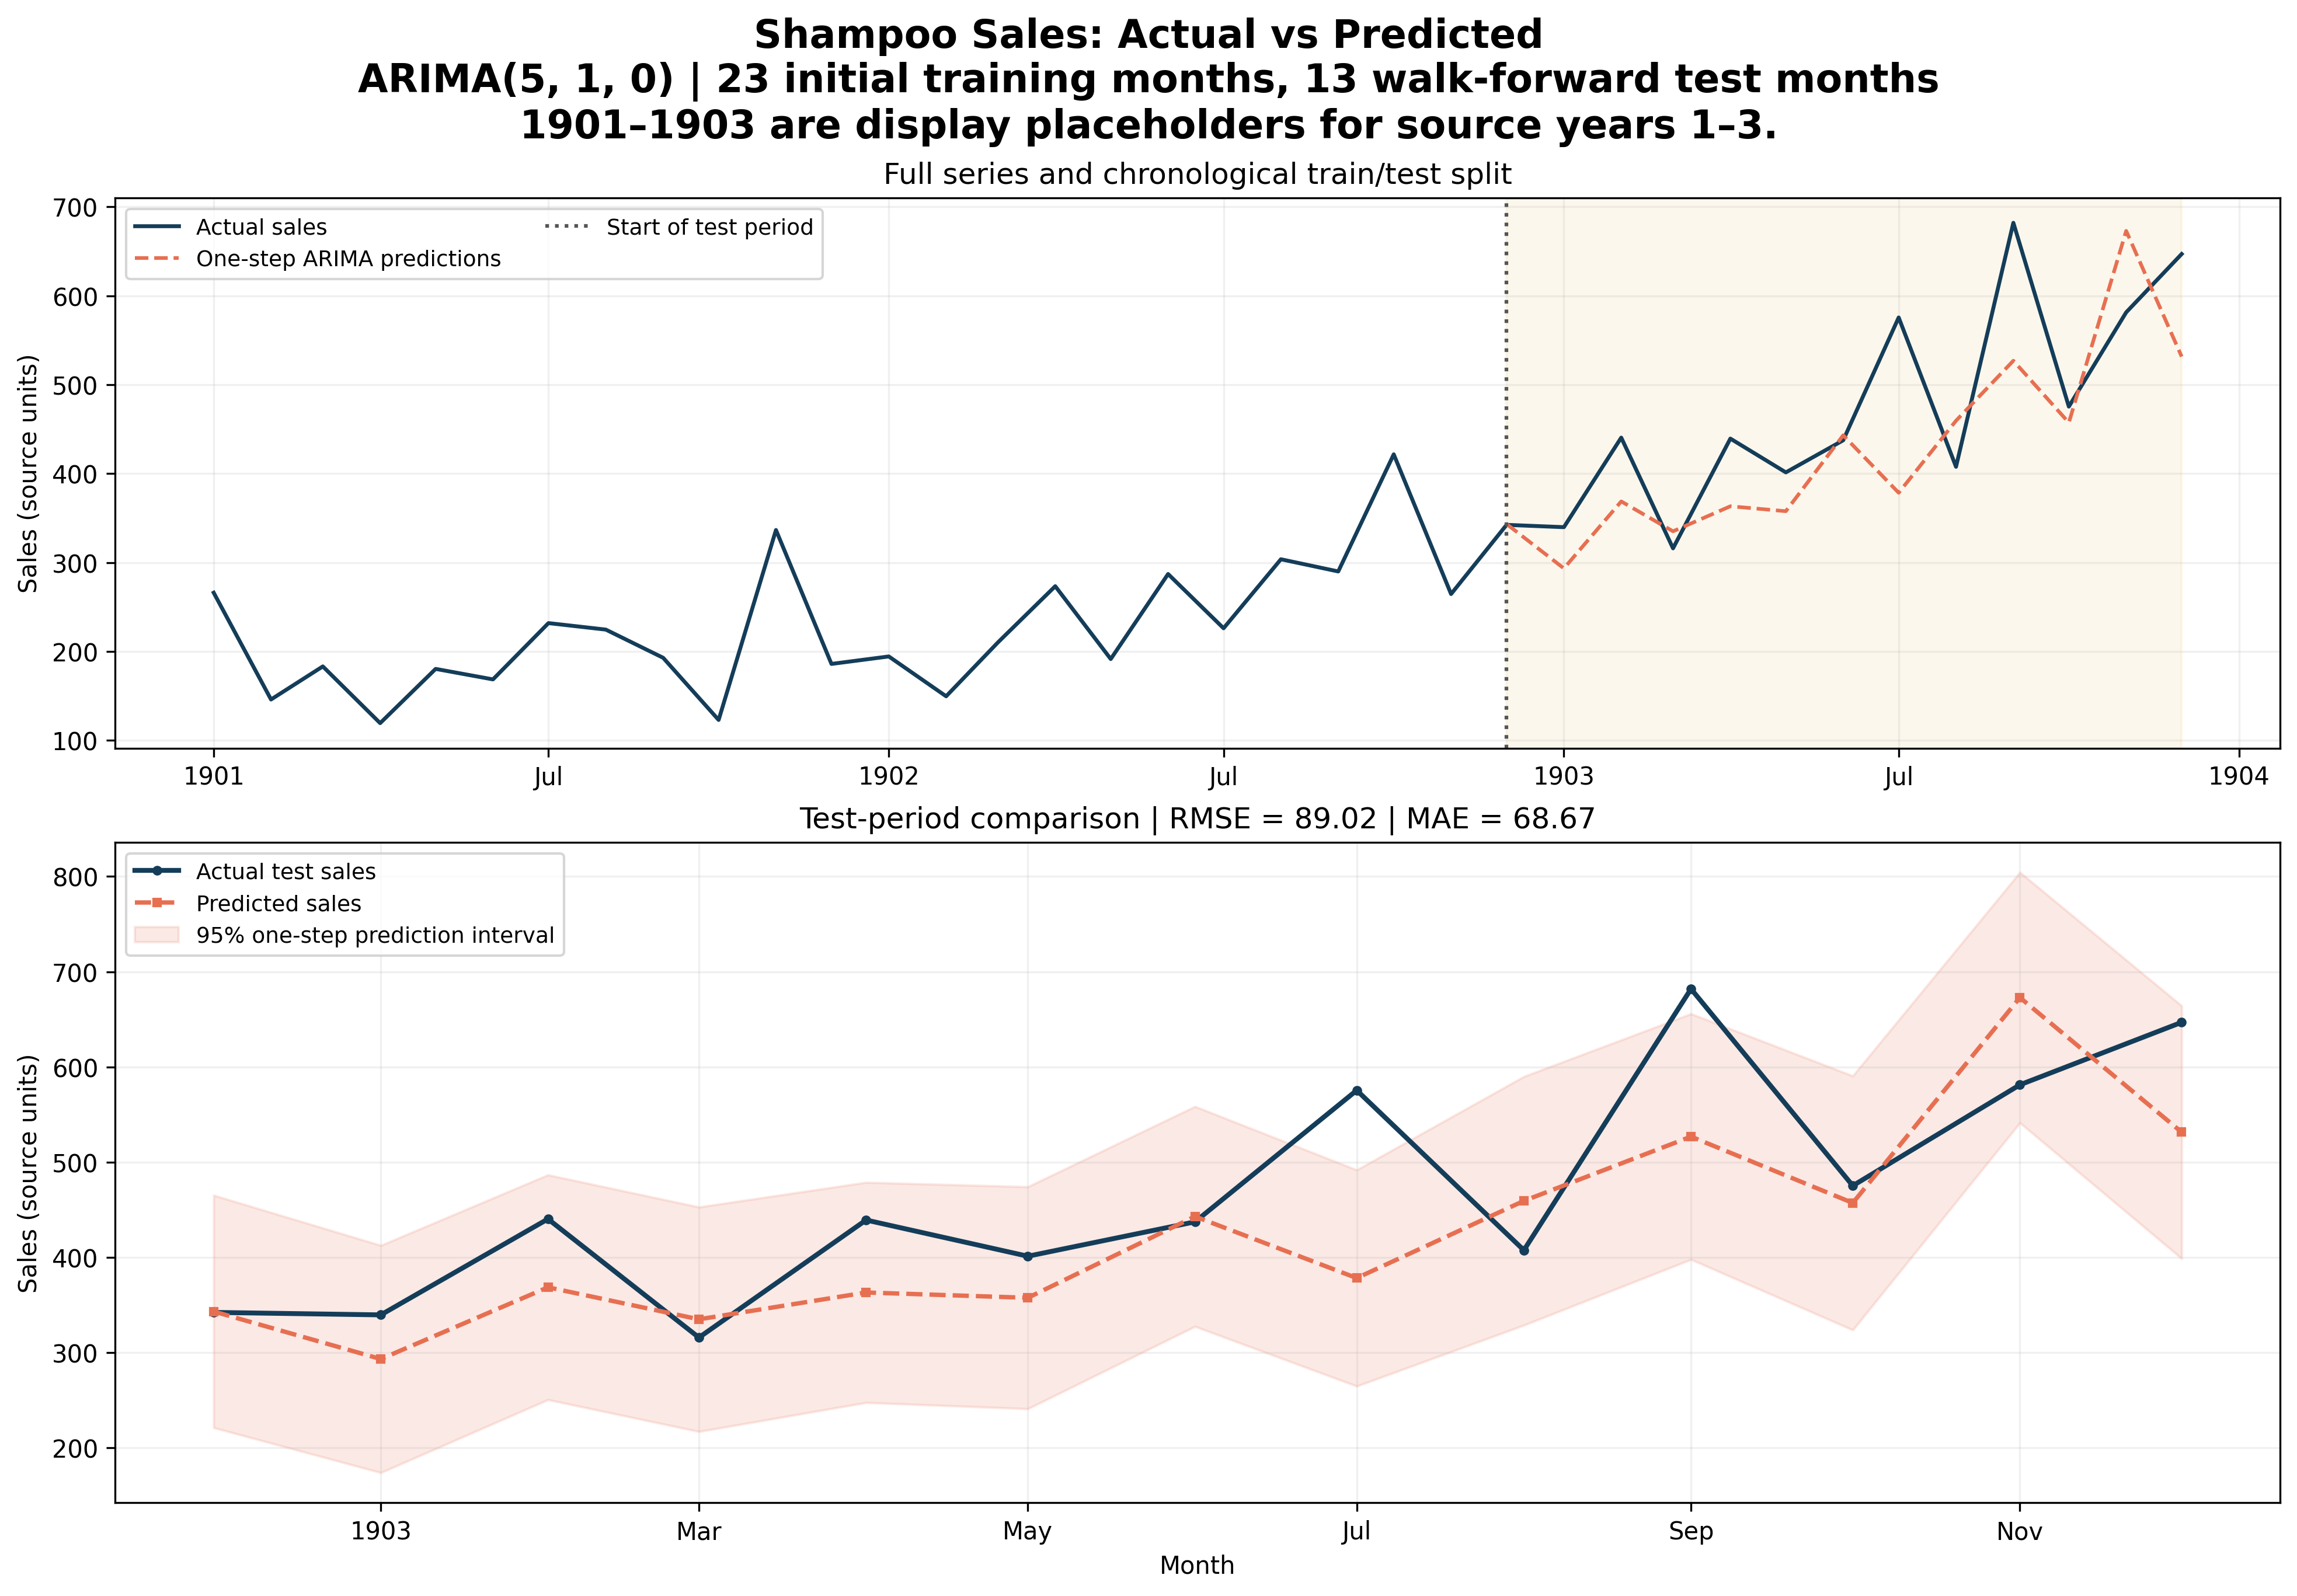

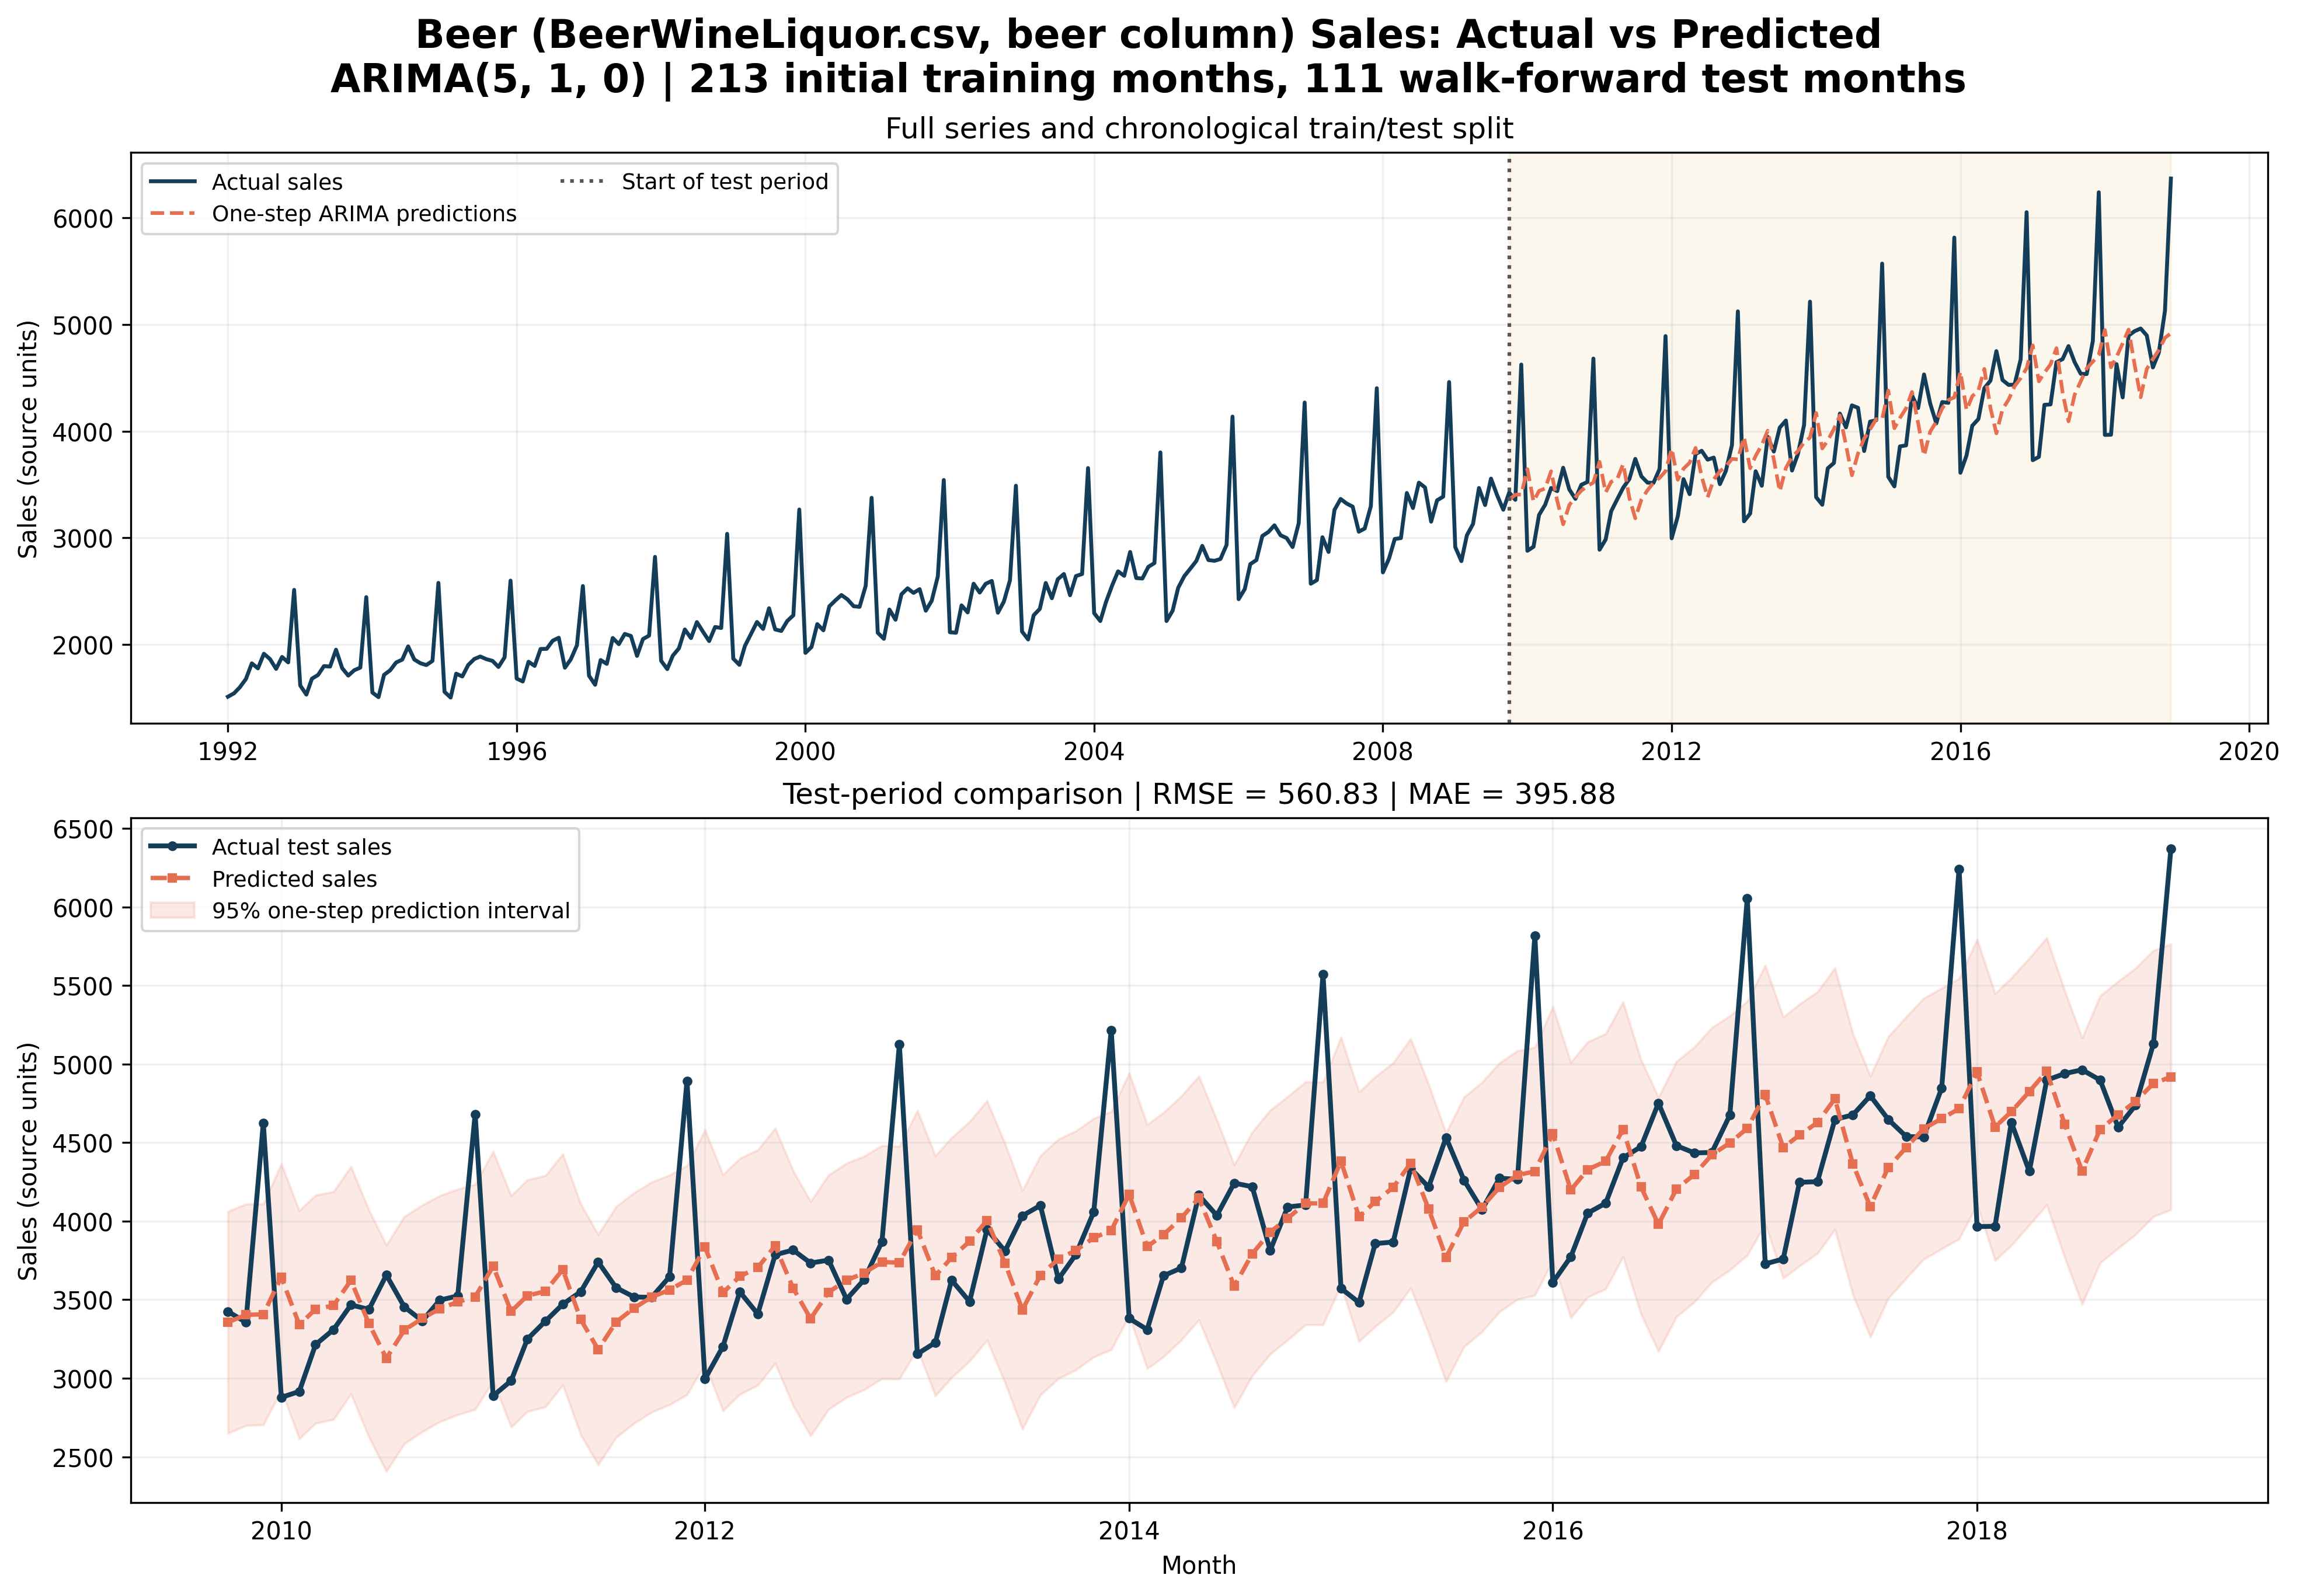

In [4]:
from IPython.display import display, Image
for name in ['shampoo','beer']:
    display(Image(filename=str(ROOT/f'figures/{name}_arima_actual_vs_predicted.png'),width=1100))


## 4. Results and interpretation

In [5]:
from IPython.display import Markdown
metrics=pd.read_csv(ROOT/'results/forecast_metrics.csv')
display(metrics)
summary=json.loads((ROOT/'results/run_summary.json').read_text())
print(json.dumps(summary,indent=2))
display(Markdown((ROOT/'README.md').read_text(encoding='utf-8')))


,dataset,model,train_months,test_months,MAE,RMSE,MAPE_percent
0,shampoo,"ARIMA(5,1,0)",23,13,68.669329,89.021056,13.298060
1,shampoo,Naive: last month,23,13,112.446154,133.155993,23.759301
2,shampoo,Seasonal naive: last year,23,13,211.192308,235.075845,43.779726
3,beer,"ARIMA(5,1,0)",213,111,395.876238,560.825570,9.520270
4,beer,Naive: last month,213,111,432.261261,729.076010,10.835885
5,beer,Seasonal naive: last year,213,111,158.441441,184.355048,3.846105


{
  "shampoo": {
    "total_months": 36,
    "train_months": 23,
    "test_months": 13,
    "start": "1901-01-01",
    "end": "1903-12-01",
    "test_start": "1902-12-01",
    "test_end": "1903-12-01",
    "interval_coverage": 0.8461538461538461,
    "failed_convergence": 0
  },
  "beer": {
    "total_months": 324,
    "train_months": 213,
    "test_months": 111,
    "start": "1992-01-01",
    "end": "2018-12-01",
    "test_start": "2009-10-01",
    "test_end": "2018-12-01",
    "interval_coverage": 0.8288288288288288,
    "failed_convergence": 0
  },
  "configuration": {
    "order": [
      5,
      1,
      0
    ],
    "train_fraction": 0.66,
    "method": "Expanding-window, one-step-ahead, refit at every test month",
    "versions": {
      "python": "3.12.14",
      "numpy": "2.1.3",
      "pandas": "2.2.3",
      "statsmodels": "0.14.4",
      "matplotlib": "3.9.2"
    }
  }
}


# ARIMA Sales Forecasting — Shampoo and Beer

Joanne Mesadieu

Forecast monthly shampoo and beer sales using the supplied ARIMA notebook and upload plots comparing predictions with actual sales.

## Required plots

![Shampoo actual vs predicted](figures/shampoo_arima_actual_vs_predicted.png)

![Beer actual vs predicted](figures/beer_arima_actual_vs_predicted.png)

## Data

The supplied shampoo.csv contains 36 monthly sales observations. Relative source labels 1-01 through 3-12 are displayed as 1901-01 through 1903-12 to match the supplied notebook. These are plotting placeholders, not independently verified calendar years. BeerWineLiquor.csv contains 324 monthly observations from January 1992 through December 2018 in its beer column. The filename is retained; its contents have not been independently verified as beer-only revenue. Sales units are not stated in the uploads, so figures use source units. Both series are checked for missing values, duplicate dates and missing months; no values are imputed.

## Forecasting method

Both series use statsmodels.tsa.arima.model.ARIMA with order=(5,1,0), preserving the supplied example. p=5 uses five autoregressive lags, d=1 differences the series once, and q=0 has no moving-average term. The first int(0.66 × N) observations form the initial training set: 23 shampoo months and 213 beer months. The remaining 13 and 111 months form the test periods. No random shuffle is used.

For every test month: fit ARIMA on the expanding history, predict exactly the next month, save its 95% prediction interval, then add the newly observed actual sale to history. Test observations become available only after their own prediction is made. This is one-step walk-forward evaluation, not a single forecast of the entire test horizon from the original training cutoff. No parameters are tuned using the test results.

## Results

| Dataset | Model | Train months | Test months | MAE | RMSE | MAPE (%) |
|---|---|---:|---:|---:|---:|---:|
| Shampoo | ARIMA(5,1,0) | 23 | 13 | 68.669 | 89.021 | 13.30 |
| Shampoo | Naive: last month | 23 | 13 | 112.446 | 133.156 | 23.76 |
| Shampoo | Seasonal naive: last year | 23 | 13 | 211.192 | 235.076 | 43.78 |
| Beer | ARIMA(5,1,0) | 213 | 111 | 395.876 | 560.826 | 9.52 |
| Beer | Naive: last month | 213 | 111 | 432.261 | 729.076 | 10.84 |
| Beer | Seasonal naive: last year | 213 | 111 | 158.441 | 184.355 | 3.85 |

Shampoo: ARIMA RMSE is 89.021. The lowest-RMSE method among these three fixed methods is ARIMA(5,1,0) (89.021).

Beer: ARIMA RMSE is 560.826. The lowest-RMSE method among these three fixed methods is Seasonal naive: last year (184.355).

Metrics are calculated automatically from aligned test-date CSVs. MAE is mean absolute error; RMSE is the square root of mean squared error; MAPE is mean absolute percentage error. Lower is better. Naive and seasonal-naive benchmarks forecast the previous month and the same month one year earlier, respectively, using only available history.

## Interpretation and limitations

The beer series has recurring annual peaks, particularly near year end. A nonseasonal ARIMA(5,1,0) need not reproduce these well; a seasonal ARIMA model with period 12 would be a useful follow-up. The task’s fixed ARIMA specification is retained instead of selecting a different model after viewing the test outcomes. Shampoo has only three years of data, making estimation and evaluation sensitive to a few observations. Prediction intervals depend on model assumptions and are not guarantees. Errors are in each dataset’s original scale and should not be directly compared across datasets.

Fits not reporting optimizer convergence: shampoo 0, beer 0. Full warnings are saved in results/fit_warnings.csv.

## Run

Use Python 3.12. From the repository root:
```bash
python -m pip install -r requirements.txt
python src/arima_forecasting.py
```
Or run all cells in ARIMA_Sales_Forecasting.ipynb. The notebook is self-contained: it includes the small supplied CSVs and executable analysis source, creates the project folders if necessary, and writes every figure and CSV. The original teaching notebook is preserved in reference/ARIMA_original.ipynb.

## Submission

Publish this project as a public GitHub repository named Joanne_Mesadieu_ARIMA_Sales_Forecasting. Submit the actual repository URL and upload figures/shampoo_arima_actual_vs_predicted.png and figures/beer_arima_actual_vs_predicted.png to the assignment. A repository link is valid only after it has actually been published; no URL is fabricated in this project.

## Software versions

```json
{
  "python": "3.12.14",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "statsmodels": "0.14.4",
  "matplotlib": "3.9.2"
}
```

## References

Inputs: user-provided shampoo.csv, BeerWineLiquor.csv and ARIMA.ipynb. Documentation: https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html and https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMAResults.get_forecast.html

## 5. Validate the exported predictions
The following checks verify exact test-date alignment, chronological training counts, valid prediction intervals, and metrics recalculated from the saved predictions.

In [6]:
import numpy as np
for name in ['shampoo','beer']:
    predictions=pd.read_csv(ROOT/f'results/{name}_actual_vs_predicted.csv',parse_dates=['date'])
    expected=summary[name]
    assert len(predictions)==expected['test_months']
    assert predictions.date.is_monotonic_increasing and predictions.date.is_unique
    assert predictions.training_observations.tolist()==list(range(expected['train_months'],expected['total_months']))
    assert (predictions.lower_95<=predictions.upper_95).all()
    rmse=np.sqrt(np.mean((predictions.actual-predictions.predicted)**2))
    saved=metrics[(metrics.dataset==name)&(metrics.model=='ARIMA(5,1,0)')].RMSE.iloc[0]
    assert np.isclose(rmse,saved)
    print(name,':',len(predictions),'aligned forecasts; saved RMSE verified.')


shampoo : 13 aligned forecasts; saved RMSE verified.
beer : 111 aligned forecasts; saved RMSE verified.


## Submission
Upload `figures/shampoo_arima_actual_vs_predicted.png` and `figures/beer_arima_actual_vs_predicted.png` as requested. Publish this project in GitHub and submit the actual repository link. Saving a notebook or ZIP alone does not create a GitHub repository.